In [127]:
import numpy as np
import copy
import subprocess
from pathlib import Path
import matplotlib.pyplot as plt
import pickle
import os, shutil, tempfile
from concurrent.futures import ThreadPoolExecutor

In [128]:
# some const things
def relu(x):
	return np.maximum(x,0)

PARAMS = [
    "children_to_ctx",
    "W1", "b1",
    "W2", "b2",
    "W3"
]

KITES = os.path.abspath("./build/kites-cli")
PROG  = os.path.abspath("test.s")

In [ ]:
# bring randomly generated instructions
def bring_shit(len_program=300, seed=0):
	if not seed:
		seed=np.random.randint(1,2**31)
	result=subprocess.run(["./rand_gen","test.s",str(seed),str(len_program)]
							,text=True,
							capture_output=True
						)
	print(result.stderr)
	result=subprocess.run(["./build/kites-cli","test.s","--reorder","2","--vm","rv5-h-nf"]
						,text=True,
						capture_output=True
						)

	# print(result.stderr)
	raw_data=np.fromfile("/tmp/ml/input_adj.bin",dtype=np.int32)
	num_instructions=int(raw_data[0])

	adjmatrix=raw_data[1:].reshape((num_instructions,num_instructions)).astype(np.float32) # weighted edges

	me=np.fromfile("/tmp/ml/input_me.bin",dtype=np.int32)
	me_vector = me.reshape((num_instructions,5)).astype(np.float32) # num_inst x 5 in og order
	#print(adjmatrix)
	return adjmatrix, me_vector

In [130]:
# the goat model
class Model:
	def __init__(self):
		# initial matrix
		self.children_to_ctx = np.random.randn(59, 65) * np.sqrt(2 / 65)

		# mlp matrices
		self.W1 = np.random.randn(128,64) * np.sqrt(2 / 64)
		self.b1 = np.random.rand(128)

		self.W2 = np.random.randn(32,128) * np.sqrt(2 / 128)
		self.b2 = np.random.rand(32)

		self.W3 = np.random.randn(1,32) * np.sqrt(2 / 32)

	def me_to_id_all(self, me, adj):
		n = len(me)
		ids = np.concatenate([me, np.zeros((n, 59))], axis=1)
		for i in range(n - 1, -1, -1):
			w = adj[i]; mask = w > 0
			if mask.any():
				agg = (w[mask] @ ids[mask]) / w[mask].sum()      # edge-weighted mean
				ids[i, 5:] = np.tanh(self.children_to_ctx @ np.r_[w[mask].sum(), agg])
		return ids

	def priority_setter(self, instruction_id_array):
		priorities = relu(relu(instruction_id_array @ self.W1.T + self.b1) @ self.W2.T + self.b2) @ self.W3.T
		return priorities
		

In [ ]:

def eval_candidate(job):
    w, adj, me, wid = job
    wd = Path(tempfile.mkdtemp(prefix=f"es{wid}_"))  # private cwd
    (wd / "ml").mkdir()
    try:
        m = Model(); set_weights(m, w)
        m.priority_setter(m.me_to_id_all(me, adj)).tofile(wd / "ml" / "priority_out.bin")
        subprocess.run([KITES, PROG, "--compare-reorder", "3", "--vm", "rv5-h-nf",
                        "--cycles-original", "c1.txt", "--cycles-modified", "c2.txt"],
                       cwd=wd, text=True, capture_output=True, timeout=120)
        c1 = int((wd / "c1.txt").read_text().split()[-1])
        c2 = int((wd / "c2.txt").read_text().split()[-1])
        return (c1 - c2) / c1
    finally:
        shutil.rmtree(wd, ignore_errors=True)

pool = ThreadPoolExecutor(max_workers=os.cpu_count())   # create once, reuse every generation

In [132]:
# for a model returns an array of all weights
def get_weights(model):
    return np.concatenate([getattr(model, name).flatten() for name in PARAMS])

# given weight array, sets the weights
def set_weights(model, weights):
    start = 0

    for name in PARAMS:
        old = getattr(model, name)
        size = old.size

        new = weights[start:start + size].reshape(old.shape)
        setattr(model, name, new.copy())

        start += size

def es_step(model, me_vector, adjmatrix, N=64, sigma=0.05, alpha=0.03):
    w = get_weights(model)
    half = np.random.randn(N // 2, w.size)
    noise = np.concatenate([half, -half])
    # raw = np.empty(N)
    # for i in range(N):
    #     cand = copy.deepcopy(model); set_weights(cand, w + sigma * noise[i])
    #     raw[i] = reward_fn(cand, me_vector, adjmatrix)
    jobs = [(w + sigma * noise[i], adjmatrix, me_vector, i) for i in range(N)]
    raw = np.array(list(pool.map(eval_candidate, jobs))) # would calculate rewards
    
    ranks = np.empty(N); ranks[raw.argsort()] = np.arange(N)
    set_weights(model, w + alpha * ((ranks / (N - 1) - 0.5) @ noise) / (N * sigma))
    return raw.mean()  

In [133]:
CoRRL = Model()

In [ ]:
# restoring a previously trained model to train again
with open("Weights.pkl", "rb") as f:
	save_data = pickle.load(f)

CoRRL.children_to_ctx = save_data["children_to_ctx"].copy()
CoRRL.W1 = save_data["W1"].copy()
CoRRL.b1 = save_data["b1"].copy()
CoRRL.W2 = save_data["W2"].copy()
CoRRL.b2 = save_data["b2"].copy()
CoRRL.W3 = save_data["W3"].copy()


Done with 1/100 random generations. With current reward = 0.23094919786096257
Testing progress

Reward = 0.18452380952380953 for 1694909363

Reward = 0.20754716981132076 for 748302702

Done with 2/100 random generations. With current reward = 0.23288272471910115

Done with 3/100 random generations. With current reward = 0.17968749999999997

Done with 4/100 random generations. With current reward = 0.25051510989010994

Done with 5/100 random generations. With current reward = 0.24159307065217395

Done with 6/100 random generations. With current reward = 0.22323994252873564

Done with 7/100 random generations. With current reward = 0.20658682634730544

Done with 8/100 random generations. With current reward = 0.21716994382022475

Done with 9/100 random generations. With current reward = 0.21305338541666669

Done with 10/100 random generations. With current reward = 0.2193181818181818

Done with 11/100 random generations. With current reward = 0.11889022435897435

Done with 12/100 random

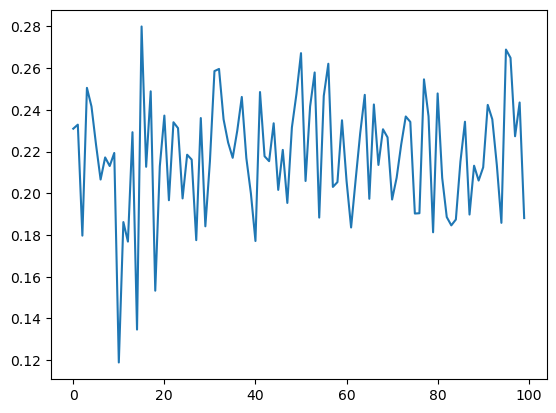

In [134]:
# training
if __name__ == "__main__":
	rng = np.random.default_rng()
	seeds_vec = rng.integers(low=1, high=2**31, size=2)

	all_rewards = []
	how_many_assem = 100
	for i in range(how_many_assem):
		adjmatrix, me_vector = bring_shit(100)

		# curr_reward = reward(CoRRL, me_vector, adjmatrix)
		
		curr_reward = es_step(CoRRL, me_vector=me_vector, adjmatrix=adjmatrix, N=64)
		all_rewards.append(curr_reward)

		print(f"Done with {i+1}/{how_many_assem} random generations. With current reward = {curr_reward}")


		if i%20 == 0:
			print("Testing progress")
			for seed in seeds_vec:
				adjmatrix, me_vector = bring_shit(100, int(seed))
				curr_reward = eval_candidate((get_weights(CoRRL), adjmatrix, me_vector, 0))
				print(f"Reward = {curr_reward} for {seed}")


	plt.plot(all_rewards)
	plt.show()


In [ ]:
# saving all the brains -- saves the whole BrainBatch as a dict of arrays
save_data = {
	"children_to_ctx": CoRRL.children_to_ctx, "W1": CoRRL.W1, "b1": CoRRL.b1, "W2": CoRRL.W2, "b2": CoRRL.b2, "W3": CoRRL.W3
}
with open("./src/reorder/Weights.pkl", "wb") as f:
	pickle.dump(save_data, f)
with open("Weights.pkl", "wb") as f:
	pickle.dump(save_data, f)